In [27]:
import pandas as pd
import polars as pl
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns


In [28]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_output = '../../../1_allele_collection/3_outputs'

In [29]:
orf_distances = pl.read_csv(f'{outputs_dir}/orf_distances.csv')
df = pl.read_csv(f'{outputs_dir}/edges_df.csv')


In [30]:
# dedup
df = df.with_columns(
    pl.when(pl.col("aa_change").is_null())
    .then(pl.lit("wt"))
    .otherwise(pl.col("aa_change"))
    .alias("aa_change")
)
df = df.with_columns(
    (pl.col("symbol") + "_" + 
     pl.col("ad_symbol") + "_" + 
     pl.col("aa_change")).alias("ppi_group_clean")
)

df = df.sort("db_mut_id", descending=True).unique(subset=["ppi_group_clean"], keep="first")

df

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,unique_id,manual_score_growth_updated,contamination,outlier_score,outlier_size_score,outlier_flag,size_score_raw,size_score,ad_symbol,symbol,gene_variant,aa_change,clinvar_clnsig_clean_pp_strict,splicing_variant,db_seq_final,clinvar_clnsig_clean,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,manual_correction_applied,consensus_score,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc,ppi_group_clean
str,str,str,str,str,str,i64,bool,i64,str,i64,i64,str,str,str,str,f64,f64,i64,i64,i64,f64,bool,bool,bool,bool,f64,f64,str,str,str,str,str,bool,str,str,str,str,str,str,i64,i64,str,bool,f64,f64,f64,f64,f64,str
"""VUSAPWT6B1r05_024""","""K17""","""VUSAPWT6B1r05_019_020_021_022_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,199,null,7652,1800,"""VUSMutY8Dh008""","""A08""","""CEGSint_Y8A6_1""","""C02""",26.827451,0.0,63,1,253191,0.0,false,false,false,false,1690.129429,1.573677,"""SYTL4""","""STXBP1""","""STXBP1_Arg190Trp""","""Arg190Trp""","""Pathogenic""",false,"""Y""","""Pathogenic""","""7652.0_1800.0_VUSAPWT6B1""","""7652.0_1800.0_LWH25_VUSAPWT6B1""","""199.0_7652.0_1800.0_VUSAPWT6B1""","""199.0_7652.0_VUSAPWT6B1""",1,1,"""Y""",false,4.4639,9.252171,0.0,539.451518,-6.62809,"""STXBP1_SYTL4_Arg190Trp"""
"""VUSAPWT1B1r05_008""","""K11""","""VUSAPWT1B1r05_007_008_009_010_…","""VUSAPWT1B1""","""r11""","""LWH25""",1,false,13662,null,70497,3826,"""VUSMutY8Dh004""","""C04""","""CEGSint_Y8A_5""","""H07""",266.962099,2.0,550,1,293865,2.0,false,false,false,false,146829.154459,136.712434,"""CYSRT1""","""AGXT""","""AGXT_Gly161Arg""","""Gly161Arg""","""Pathogenic""",false,"""Y""","""Pathogenic""","""70497.0_3826.0_VUSAPWT1B1""","""70497.0_3826.0_LWH25_VUSAPWT1B…","""13662.0_70497.0_3826.0_VUSAPWT…","""13662.0_70497.0_VUSAPWT1B1""",1,1,"""Y""",false,117.095717,8.985773,2.0,358.208705,-1.604866,"""AGXT_CYSRT1_Gly161Arg"""
"""VUSAPWT6B1r05_012""","""K23""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,13182,null,70368,205543,"""VUSMutY8Dh028""","""E11""","""CEGSint_Y8A6_1""","""A08""",645.409176,3.0,1109,1,248589,3.0,false,false,false,false,715758.776737,666.442064,"""TERF1""","""KCTD7""","""KCTD7_Asp115Tyr""","""Asp115Tyr""","""Pathogenic""",false,"""Y""","""Pathogenic""","""70368.0_205543.0_VUSAPWT6B1""","""70368.0_205543.0_LWH25_VUSAPWT…","""13182.0_70368.0_205543.0_VUSAP…","""13182.0_70368.0_VUSAPWT6B1""",1,1,"""Y""",false,669.664964,10.602781,3.0,462.496518,0.533034,"""KCTD7_TERF1_Asp115Tyr"""
"""VUSAPWT1B2r05_026""","""K21""","""VUSAPWT1B2r05_025_026_027_028_…","""VUSAPWT1B2""","""r11""","""LWH25""",1,false,5093,null,5723,201966,"""VUSMutY8Dh029""","""B08""","""CEGSint_Y8A_4""","""F07""",487.613076,3.0,1089,1,130291,3.0,false,false,false,false,531010.639441,494.423314,"""TMEM79""","""SFTPC""","""SFTPC_Arg167Gln""","""Arg167Gln""","""Conflicting""",false,"""Y""","""Conflicting""","""5723.0_201966.0_VUSAPWT1B2""","""5723.0_201966.0_LWH25_VUSAPWT1…","""5093.0_5723.0_201966.0_VUSAPWT…","""5093.0_5723.0_VUSAPWT1B2""",1,1,"""Y""",true,480.578311,5.935809,3.0,542.319331,-0.17403,"""SFTPC_TMEM79_Arg167Gln"""
"""VUSAPWT6B1r05_015""","""M17""","""VUSAPWT6B1r05_013_014_015_016_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,70382,null,71001,205676,"""VUSMutY8Dh023""","""D10""","""CEGSint_Y8A6_1""","""G06""",560.649693,3.0,1100,1,250959,3.0,false,false,false,false,616714.662281,574.222218,"""JPH4""","""UBQLN2""","""UBQLN2_Pro509Ser""","""Pro509Ser""","""VUS""",false,"""Y""","""VUS""","""71001.0_205676.0_VUSAPWT6B1""","""71001.0_205676.0_LWH25_VUSAPWT…","""70382.0_71001.0_205676.0_VUSAP…","""70382.0_71001.0_VUSAPWT6B1""",1,1,"""Y""",false,561.385848,5.586043,3.0,42

In [31]:

df.select(['symbol', 'db_orf_id', 'aa_change', 'db_mut_id', 'ad_symbol', 'ad_orf_id', 'clinvar_clnsig_clean', 'consensus_score', 'wt_consensus_score', 'log2fc']).write_csv(f"{outputs_dir}/ppi_level_scores_minimal_Leo.csv")

orf_distances[['symbol', 'db_orf_id', 'aa_change', 'db_mut_id', 'gene_variant' ,'clinvar_clnsig_clean', 'norm_dist_rms']].write_csv(f"{outputs_dir}/orf_distances_minimal_Leo.csv")

In [32]:
df

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,unique_id,manual_score_growth_updated,contamination,outlier_score,outlier_size_score,outlier_flag,size_score_raw,size_score,ad_symbol,symbol,gene_variant,aa_change,clinvar_clnsig_clean_pp_strict,splicing_variant,db_seq_final,clinvar_clnsig_clean,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,manual_correction_applied,consensus_score,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc,ppi_group_clean
str,str,str,str,str,str,i64,bool,i64,str,i64,i64,str,str,str,str,f64,f64,i64,i64,i64,f64,bool,bool,bool,bool,f64,f64,str,str,str,str,str,bool,str,str,str,str,str,str,i64,i64,str,bool,f64,f64,f64,f64,f64,str
"""VUSAPWT6B1r05_024""","""K17""","""VUSAPWT6B1r05_019_020_021_022_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,199,null,7652,1800,"""VUSMutY8Dh008""","""A08""","""CEGSint_Y8A6_1""","""C02""",26.827451,0.0,63,1,253191,0.0,false,false,false,false,1690.129429,1.573677,"""SYTL4""","""STXBP1""","""STXBP1_Arg190Trp""","""Arg190Trp""","""Pathogenic""",false,"""Y""","""Pathogenic""","""7652.0_1800.0_VUSAPWT6B1""","""7652.0_1800.0_LWH25_VUSAPWT6B1""","""199.0_7652.0_1800.0_VUSAPWT6B1""","""199.0_7652.0_VUSAPWT6B1""",1,1,"""Y""",false,4.4639,9.252171,0.0,539.451518,-6.62809,"""STXBP1_SYTL4_Arg190Trp"""
"""VUSAPWT1B1r05_008""","""K11""","""VUSAPWT1B1r05_007_008_009_010_…","""VUSAPWT1B1""","""r11""","""LWH25""",1,false,13662,null,70497,3826,"""VUSMutY8Dh004""","""C04""","""CEGSint_Y8A_5""","""H07""",266.962099,2.0,550,1,293865,2.0,false,false,false,false,146829.154459,136.712434,"""CYSRT1""","""AGXT""","""AGXT_Gly161Arg""","""Gly161Arg""","""Pathogenic""",false,"""Y""","""Pathogenic""","""70497.0_3826.0_VUSAPWT1B1""","""70497.0_3826.0_LWH25_VUSAPWT1B…","""13662.0_70497.0_3826.0_VUSAPWT…","""13662.0_70497.0_VUSAPWT1B1""",1,1,"""Y""",false,117.095717,8.985773,2.0,358.208705,-1.604866,"""AGXT_CYSRT1_Gly161Arg"""
"""VUSAPWT6B1r05_012""","""K23""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,13182,null,70368,205543,"""VUSMutY8Dh028""","""E11""","""CEGSint_Y8A6_1""","""A08""",645.409176,3.0,1109,1,248589,3.0,false,false,false,false,715758.776737,666.442064,"""TERF1""","""KCTD7""","""KCTD7_Asp115Tyr""","""Asp115Tyr""","""Pathogenic""",false,"""Y""","""Pathogenic""","""70368.0_205543.0_VUSAPWT6B1""","""70368.0_205543.0_LWH25_VUSAPWT…","""13182.0_70368.0_205543.0_VUSAP…","""13182.0_70368.0_VUSAPWT6B1""",1,1,"""Y""",false,669.664964,10.602781,3.0,462.496518,0.533034,"""KCTD7_TERF1_Asp115Tyr"""
"""VUSAPWT1B2r05_026""","""K21""","""VUSAPWT1B2r05_025_026_027_028_…","""VUSAPWT1B2""","""r11""","""LWH25""",1,false,5093,null,5723,201966,"""VUSMutY8Dh029""","""B08""","""CEGSint_Y8A_4""","""F07""",487.613076,3.0,1089,1,130291,3.0,false,false,false,false,531010.639441,494.423314,"""TMEM79""","""SFTPC""","""SFTPC_Arg167Gln""","""Arg167Gln""","""Conflicting""",false,"""Y""","""Conflicting""","""5723.0_201966.0_VUSAPWT1B2""","""5723.0_201966.0_LWH25_VUSAPWT1…","""5093.0_5723.0_201966.0_VUSAPWT…","""5093.0_5723.0_VUSAPWT1B2""",1,1,"""Y""",true,480.578311,5.935809,3.0,542.319331,-0.17403,"""SFTPC_TMEM79_Arg167Gln"""
"""VUSAPWT6B1r05_015""","""M17""","""VUSAPWT6B1r05_013_014_015_016_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,70382,null,71001,205676,"""VUSMutY8Dh023""","""D10""","""CEGSint_Y8A6_1""","""G06""",560.649693,3.0,1100,1,250959,3.0,false,false,false,false,616714.662281,574.222218,"""JPH4""","""UBQLN2""","""UBQLN2_Pro509Ser""","""Pro509Ser""","""VUS""",false,"""Y""","""VUS""","""71001.0_205676.0_VUSAPWT6B1""","""71001.0_205676.0_LWH25_VUSAPWT…","""70382.0_71001.0_205676.0_VUSAP…","""70382.0_71001.0_VUSAPWT6B1""",1,1,"""Y""",false,561.385848,5.586043,3.0,42

In [33]:
orf_distances.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("norm_dist_rms").alias("score"),
    pl.col("gene_variant").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "norm_dist_rms", "gene_variant", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/calcLLR/scores/Variants_referenceSet.csv")

orf_distances.with_columns(
    pl.col("norm_dist_rms").alias("score"),
    pl.col("gene_variant").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/calcLLR/scores/Variants_allScores.csv")

In [34]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Variants_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Variants_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_bcv.log" --bandwidth "bcv" --printTransitions  --kernel "gaussian" --outlierSuppression 0.1
# Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Variants_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Variants_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
# Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Variants_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Variants_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_default.log" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
# Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Variants_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Variants_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_nrd.log" --bandwidth "nrd" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
# Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Variants_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Variants_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_sj.log" --printTransitions --bandwidth "SJ" --kernel "gaussian" --outlierSuppression 0.1

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-31_15:39:14 INFO: Reading input 
2025-12-31_15:39:14 INFO: Calculating densties 


Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-12-31_15:39:15 INFO: Drawing LLR plot 
2025-12-31_15:39:15 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-31_15:39:15 INFO: Category transitions:  
0.547 : none -> patho.support
0.641 : patho.support -> patho.moderate
2025-12-31_15:39:15 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-31_15:39:15 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/Variants_LLR_score_bcv.csv 
2025-12-31_15:39:15 INFO: Done! 


In [38]:
LLR_threshold = 0.547

# add ppi_hit column

orf_distances = orf_distances.with_columns(
    pl.when(pl.col("norm_dist_rms") >= LLR_threshold)
    .then(True)
    .otherwise(False)
    .alias("ppi_hit")
)

cols_to_keep = ['db_orf_id',
 'db_mut_id',
 'num_edges',
 'clinvar_clnsig_clean',
 'norm_dist_rms',
 'symbol',
 'gene_variant',
 'aa_change',
 'clinvar_clnsig_clean_pp_strict',
 'ppi_hit']

orf_distances = orf_distances.select(cols_to_keep)

orf_distances.write_csv(f'{outputs_dir}/orf_distances_final.csv')

In [ ]:
cols_to_keep = ['db_orf_id',
 'db_mut_id',
 'num_edges',
 'clinvar_clnsig_clean',
 'norm_dist_rms',
 'symbol',
 'gene_variant',
 'aa_change',
 'clinvar_clnsig_clean_pp_strict',
 'ppi_hit']

['db_orf_id',
 'db_mut_id',
 'num_edges',
 'clinvar_clnsig_clean',
 'euclid_dist_legacy',
 'euclid_dist_interactor',
 'euclid_dist_wt_imp',
 'nan_euclid_dist_rms',
 'mean_signed_difference',
 'mean_log2fc',
 'max_perturbation',
 'relative_rms_dist',
 'norm_dist_legacy',
 'norm_dist_interactor',
 'norm_dist_wt_imp',
 'norm_dist_rms',
 'norm_dist_legacy_scaled',
 'norm_dist_rms_scaled',
 'max_perturbation_normalized',
 'rank_rms',
 'rank_rel_rms',
 'composite_rank_score',
 'symbol',
 'gene_variant',
 'aa_change',
 'clinvar_clnsig_clean_pp_strict',
 'splicing_variant',
 'db_seq_final',
 'ppi_hit']

In [36]:
stop

NameError: name 'stop' is not defined

# Edges

In [ ]:
# drop WT

df = df.filter(pl.col("db_mut_id") != 0)

In [ ]:
df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("log2fc").alias("score"),
    pl.col("ppi_group").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "log2fc", "ppi_group", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv")

df.with_columns(
    pl.col("log2fc").alias("score"),
    pl.col("ppi_group").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv")

In [ ]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_bcv.log" --bandwidth "bcv" --printTransitions  --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_default.log" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_nrd.log" --bandwidth "nrd" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_sj.log" --printTransitions --bandwidth "SJ" --kernel "gaussian" --outlierSuppression 0.1

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:02 INFO: Reading input 
2025-12-29_11:55:02 INFO: Calculating densties 
2025-12-29_11:55:03 INFO: Drawing LLR plot 
2025-12-29_11:55:03 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:04 INFO: Category transitions:  
-9.033 : patho.moderate -> patho.strong
-8.840 : patho.strong -> patho.moderate
-8.271 : patho.moderate -> patho.support
-8.111 : patho.support -> none
-7.188 : none -> patho.support
-7.081 : patho.support -> patho.moderate
-6.866 : patho.moderate -> patho.strong
-6.512 : patho.strong -> patho.moderate
-5.954 : patho.moderate -> patho.support
-5.171 : patho.support -> none
-5.096 : none -> patho.support
-3.776 : patho.support -> none
-0.793 : none -> benign.support
-0.579 : benign.support -> none
0.569 : none -> benign.support
0.891 : benign.support -> none
1.181 : none -> benign.support
2025-12-29_11:55:04 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-29_11:

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:05 INFO: Reading input 
2025-12-29_11:55:05 INFO: Calculating densties 
2025-12-29_11:55:06 INFO: Drawing LLR plot 
2025-12-29_11:55:06 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:07 INFO: Category transitions:  
-8.261 : patho.moderate -> patho.support
-8.089 : patho.support -> none
-7.349 : none -> patho.support
-7.166 : patho.support -> patho.moderate
-6.898 : patho.moderate -> patho.strong
-6.544 : patho.strong -> patho.moderate
-5.975 : patho.moderate -> patho.support
-3.486 : patho.support -> none
2025-12-29_11:55:07 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-29_11:55:07 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd0.csv 
2025-12-29_11:55:07 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:07 INFO: Reading input 
2025-12-29_11:55:08 INFO: Calculating densties 
2025-12-29_11:55:08 INFO: Drawing LLR plot 
2025-12-29_11:55:09 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:09 INFO: Category transitions:  
-8.990 : patho.moderate -> patho.strong
-8.894 : patho.strong -> patho.moderate
-8.432 : patho.moderate -> patho.strong
-8.379 : patho.strong -> patho.moderate
-8.186 : patho.moderate -> patho.support
-8.046 : patho.support -> none
-7.810 : none -> benign.support
-7.606 : benign.support -> none
-7.209 : none -> patho.support
-7.134 : patho.support -> patho.moderate
-6.984 : patho.moderate -> patho.strong
-6.405 : patho.strong -> patho.moderate
-5.975 : patho.moderate -> patho.support
-5.235 : patho.support -> none
-4.978 : none -> patho.support
-4.559 : patho.support -> patho.moderate
-4.184 : patho.moderate -> patho.support
-3.819 : patho.support -> none
-3.594 : none -> patho.suppor

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:10 INFO: Reading input 
2025-12-29_11:55:10 INFO: Calculating densties 
2025-12-29_11:55:11 INFO: Drawing LLR plot 
2025-12-29_11:55:11 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:12 INFO: Category transitions:  
-8.336 : patho.moderate -> patho.support
-8.100 : patho.support -> none
-7.413 : none -> patho.support
-7.166 : patho.support -> patho.moderate
-5.997 : patho.moderate -> patho.support
-3.551 : patho.support -> none
2025-12-29_11:55:12 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-29_11:55:12 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd.csv 
2025-12-29_11:55:12 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:13 INFO: Reading input 
2025-12-29_11:55:13 INFO: Calculating densties 
2025-12-29_11:55:14 INFO: Drawing LLR plot 
2025-12-29_11:55:14 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:15 INFO: Category transitions:  
-8.175 : patho.moderate -> patho.support
-8.057 : patho.support -> none
-7.756 : none -> benign.support
-7.628 : benign.support -> none
-7.231 : none -> patho.support
-7.134 : patho.support -> patho.moderate
-6.984 : patho.moderate -> patho.strong
-6.405 : patho.strong -> patho.moderate
-5.954 : patho.moderate -> patho.support
-5.149 : patho.support -> none
-4.924 : none -> patho.support
-4.527 : patho.support -> patho.moderate
-4.194 : patho.moderate -> patho.support
-3.787 : patho.support -> none
-3.647 : none -> patho.support
-3.454 : patho.support -> none
0.698 : none -> benign.support
0.784 : benign.support -> none
1.235 : none -> benign.support
2025-12-29_11:55:15 INFO: Bootstra

In [ ]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_bcv.log" --bandwidth "bcv" --printTransitions  --kernel "biweight" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --kernel "biweight" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_default.log" --printTransitions --kernel "biweight" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_nrd.log" --bandwidth "nrd" --printTransitions --kernel "biweight" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_sj.log" --printTransitions --bandwidth "SJ" --kernel "biweight" --outlierSuppression 0.1

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:18 INFO: Reading input 
2025-12-29_11:55:18 INFO: Calculating densties 
2025-12-29_11:55:19 INFO: Drawing LLR plot 
2025-12-29_11:55:19 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:20 INFO: Category transitions:  
-9.076 : patho.moderate -> patho.strong
-8.797 : patho.strong -> patho.moderate
-8.518 : patho.moderate -> patho.strong
-8.486 : patho.strong -> patho.moderate
-8.282 : patho.moderate -> patho.support
-8.164 : patho.support -> none
-7.166 : none -> patho.support
-7.059 : patho.support -> patho.moderate
-6.866 : patho.moderate -> patho.strong
-6.544 : patho.strong -> patho.moderate
-5.965 : patho.moderate -> patho.support
-5.203 : patho.support -> none
-5.106 : none -> patho.support
-3.722 : patho.support -> none
-0.836 : none -> benign.support
-0.579 : benign.support -> none
0.559 : none -> benign.support
0.870 : benign.support -> none
1.202 : none -> benign.support
2025-12-29_11:55:2

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:21 INFO: Reading input 
2025-12-29_11:55:21 INFO: Calculating densties 
2025-12-29_11:55:22 INFO: Drawing LLR plot 
2025-12-29_11:55:22 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:23 INFO: Category transitions:  
-8.304 : patho.moderate -> patho.support
-8.153 : patho.support -> none
-7.370 : none -> patho.support
-7.145 : patho.support -> patho.moderate
-6.909 : patho.moderate -> patho.strong
-6.587 : patho.strong -> patho.moderate
-5.986 : patho.moderate -> patho.support
-3.529 : patho.support -> none
2025-12-29_11:55:23 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-29_11:55:23 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd0.csv 
2025-12-29_11:55:23 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:24 INFO: Reading input 
2025-12-29_11:55:24 INFO: Calculating densties 
2025-12-29_11:55:25 INFO: Drawing LLR plot 
2025-12-29_11:55:25 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:26 INFO: Category transitions:  
-9.012 : patho.moderate -> patho.strong
-8.851 : patho.strong -> patho.moderate
-8.454 : patho.moderate -> patho.strong
-8.357 : patho.strong -> patho.moderate
-8.196 : patho.moderate -> patho.support
-8.078 : patho.support -> none
-7.789 : none -> benign.support
-7.617 : benign.support -> none
-7.188 : none -> patho.support
-7.102 : patho.support -> patho.moderate
-6.984 : patho.moderate -> patho.strong
-6.448 : patho.strong -> patho.moderate
-5.975 : patho.moderate -> patho.support
-5.257 : patho.support -> none
-4.967 : none -> patho.support
-4.538 : patho.support -> patho.moderate
-4.259 : patho.moderate -> patho.support
-3.787 : patho.support -> none
-3.518 : none -> patho.suppor

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:26 INFO: Reading input 
2025-12-29_11:55:26 INFO: Calculating densties 
2025-12-29_11:55:27 INFO: Drawing LLR plot 
2025-12-29_11:55:27 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:28 INFO: Category transitions:  
-8.390 : patho.moderate -> patho.support
-8.175 : patho.support -> none
-7.488 : none -> patho.support
-7.145 : patho.support -> patho.moderate
-6.008 : patho.moderate -> patho.support
-3.583 : patho.support -> none
2025-12-29_11:55:28 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-29_11:55:29 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd.csv 
2025-12-29_11:55:29 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:29 INFO: Reading input 
2025-12-29_11:55:29 INFO: Calculating densties 
2025-12-29_11:55:30 INFO: Drawing LLR plot 
2025-12-29_11:55:30 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:31 INFO: Category transitions:  
-8.175 : patho.moderate -> patho.support
-8.089 : patho.support -> none
-7.209 : none -> patho.support
-7.123 : patho.support -> patho.moderate
-6.984 : patho.moderate -> patho.strong
-6.458 : patho.strong -> patho.moderate
-5.954 : patho.moderate -> patho.support
-5.246 : patho.support -> none
-4.956 : none -> patho.support
-4.495 : patho.support -> patho.moderate
-4.269 : patho.moderate -> patho.support
-3.690 : patho.support -> none
0.645 : none -> benign.support
0.805 : benign.support -> none
1.256 : none -> benign.support
2025-12-29_11:55:31 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-29_11:55:31 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR

In [ ]:
def plot_patho_benign(scores=None, metric="normalized_euclid_distance_normalized", num_edge_filter=1, title=None, threshold=None, fixed_threshold=None, log_treshold=False, clinvar_col="clinvar_clnsig_clean"):
    """
    Plot pathogenic vs benign distribution with optional threshold.
    
    Parameters:
    -----------
    scores : pl.DataFrame, optional
        DataFrame with scores and ClinVar annotations
    metric : str
        Column name containing the metric to plot
    num_edge_filter : int
        Minimum number of edges for filtering
    title : str, optional
        Plot title
    threshold : bool or float, optional
        Whether to calculate or use a threshold
    fixed_threshold : float, optional
        Fixed threshold value to use
    log_treshold : bool
        Whether to use log-scale threshold logic
    clinvar_col : str
        Column to use for ClinVar classification ('clinvar_clnsig_clean' or 'clinvar_clnsig_clean_pp_strict')
    """
    
    # Select appropriate palette based on clinvar column
    if clinvar_col == "clinvar_clnsig_clean_pp_strict":
        palette_dict = {
            'Pathogenic': "#CA7682",
            'Likely pathogenic': "#E6B1B8",
            'Benign': "#1D7AAB",
            'Likely benign': "#7DB8D9",
            'Conflicting': "#505050",
            'VUS': "#A0A0A0",
            'Others': "#E0E0E0"
        }
        pathogenic_categories = ['Pathogenic', 'Likely pathogenic']
        benign_categories = ['Benign', 'Likely benign']
    else:
        palette_dict = {
            'Pathogenic': "#CA7682",
            'Benign': "#1D7AAB",
            'Conflicting': "#505050",
            'VUS': "#A0A0A0",
            'Others': "#E0E0E0"
        }
        pathogenic_categories = ['Pathogenic']
        benign_categories = ['Benign']
    
    if scores is None:
        scores = orf_distances  # This will use the current state of orf_distances
    
    # Filter for pathogenic and benign variants
    path_filter = pl.col(clinvar_col).is_in(pathogenic_categories)
    benign_filter = pl.col(clinvar_col).is_in(benign_categories)
    
    print(f"Plotting {metric} distribution for Pathogenic and Benign variants")
    print("Total variants:", scores.shape[0])
    print("Total unique db_orf_id:", scores.select(pl.col("db_orf_id").n_unique()).item())
    print(f"Total Pathogenic variants: {scores.filter(path_filter).shape[0]}")
    print(f"Total Benign variants: {scores.filter(benign_filter).shape[0]}")
    
    # Calculate threshold if requested
    if threshold:
        path_thres = scores.filter(benign_filter)[metric].max() + 0.016
        print('path_thres:', path_thres)
        if log_treshold:
            path_thres = scores.filter(benign_filter)[metric].min() - 0.016
            print('path_thres:', path_thres)
        elif type(threshold) == float or type(threshold) == int:
            path_thres = threshold
            print('path_thres:', path_thres)
    
    if fixed_threshold:
        path_thres = fixed_threshold
        print('fixed_threshold:', path_thres)
    
    # Create plots
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    
    # KDE plot
    sns.kdeplot(
        data=scores.filter(path_filter)[metric].to_numpy(), 
        label='Pathogenic' if clinvar_col == "clinvar_clnsig_clean" else 'Pathogenic/Likely pathogenic',
        color=palette_dict['Pathogenic'], 
        fill=True, 
        ax=axes[0]
    )
    sns.kdeplot(
        data=scores.filter(benign_filter)[metric].to_numpy(), 
        label='Benign' if clinvar_col == "clinvar_clnsig_clean" else 'Benign/Likely benign',
        color=palette_dict['Benign'], 
        fill=True, 
        ax=axes[0]
    )
    
    if threshold or fixed_threshold:
        axes[0].axvline(x=path_thres, color=palette_dict['Pathogenic'], linestyle='--', label='Threshold')
    axes[0].legend()
    
    # Histogram plot
    sns.histplot(
        scores.filter(path_filter)[metric].to_numpy(), 
        label='Pathogenic' if clinvar_col == "clinvar_clnsig_clean" else 'Pathogenic/Likely pathogenic',
        color=palette_dict['Pathogenic'], 
        kde=True, 
        ax=axes[1]
    )
    sns.histplot(
        scores.filter(benign_filter)[metric].to_numpy(), 
        label='Benign' if clinvar_col == "clinvar_clnsig_clean" else 'Benign/Likely benign',
        color=palette_dict['Benign'], 
        kde=True, 
        ax=axes[1]
    )
    
    if threshold or fixed_threshold:
        axes[1].axvline(x=path_thres, color=palette_dict['Pathogenic'], linestyle='--', label='Threshold')
    
    plt.subplots_adjust(hspace=.05)
    if title is not None:
        plt.suptitle(title)
    else:
        plt.suptitle(f"Distribution of {metric} scores")
    plt.show()
    
    # Filter by number of edges if needed
    if num_edge_filter > 1:
        benign_scores = scores.filter(benign_filter).filter(pl.col("num_edges") >= num_edge_filter)
        path_scores = scores.filter(path_filter).filter(pl.col("num_edges") >= num_edge_filter)
        vus_scores = scores.filter(pl.col(clinvar_col) == "VUS").filter(pl.col("num_edges") >= num_edge_filter)
        conf_scores = scores.filter(pl.col(clinvar_col) == "Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
    else:
        benign_scores = scores.filter(benign_filter)
        path_scores = scores.filter(path_filter)
        vus_scores = scores.filter(pl.col(clinvar_col) == "VUS")
        conf_scores = scores.filter(pl.col(clinvar_col) == "Conflicting")
    
    # Print threshold statistics
    if threshold or fixed_threshold:
        if log_treshold:
            print(f"Benign: {benign_scores.filter(pl.col(metric) < path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) < path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) < path_thres).shape[0]} ({path_scores.filter(pl.col(metric) < path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) < path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) < path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) < path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) < path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")
        else:
            print(f"Benign: {benign_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) >= path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({path_scores.filter(pl.col(metric) >= path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) >= path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) >= path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")

Plotting log2fc distribution for Pathogenic and Benign variants
Total variants: 1859
Total unique db_orf_id: 75
Total Pathogenic variants: 907
Total Benign variants: 116


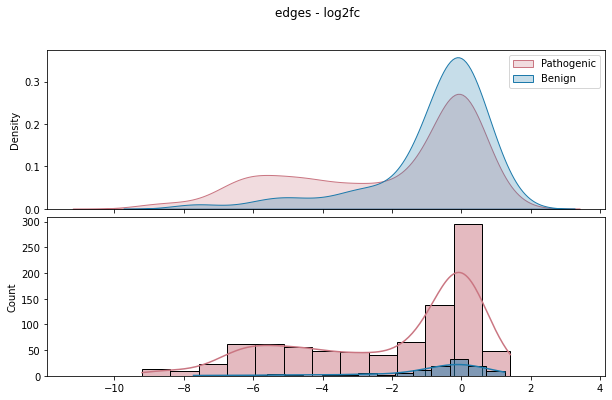

In [ ]:
plot_patho_benign(scores=df, metric='log2fc', title=f"edges - log2fc")

In [ ]:
def perturbation_LLR(df):
    df = df.copy()
    ASSUMED_PERTURBATION_SIZE = -5.0
    ASSUMED_PERTURBATION_DISTRIBUTION = 1.5
    ASSUMED_NON_PERTURBATION_DISTRIBUTION = 0.5
    ASSUMED_PERTURBATION_BOUND = -1.0

    # in the scipy API: loc is mean, scale is stddev
    loglikelihood_unperturbed_model = stats.norm.logpdf(
        df["log2FC_combined"],
        loc=0,
        scale=df["error_log2FC_combined"] + ASSUMED_NON_PERTURBATION_DISTRIBUTION,
    )

    log2fc = df["log2FC_combined"].to_numpy()
    error_log2fc = df["error_log2FC_combined"].to_numpy()

    var_prior = ASSUMED_PERTURBATION_DISTRIBUTION**2
    var_measurement = error_log2fc**2
    sigma_combined = np.sqrt(var_prior + var_measurement)

    # Marginal (untruncated) distribution of y
    log_py = stats.norm.logpdf(
        log2fc, loc=ASSUMED_PERTURBATION_SIZE, scale=sigma_combined
    )

    # Posterior of theta | y under untruncated normal prior
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (
        ASSUMED_PERTURBATION_SIZE / var_prior + log2fc / var_measurement
    )
    t = (ASSUMED_PERTURBATION_BOUND - mu_post) / sigma_post
    # Probability that θ ≤ bound under this posterior
    log_post_cdf = stats.norm.logcdf(t)

    # Prior truncation normalising constant
    alpha = (
        ASSUMED_PERTURBATION_BOUND - ASSUMED_PERTURBATION_SIZE
    ) / ASSUMED_PERTURBATION_DISTRIBUTION
    log_Z = stats.norm.logcdf(alpha)

    loglikelihood_perturbed_model = log_py + log_post_cdf - log_Z
    df["perturbation_LLR"] = (
        loglikelihood_unperturbed_model - loglikelihood_perturbed_model
    )
    return df

In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import polars as pl

def perturbation_LLR_edge(df, default_error=0.5):
    """
    Calculates LLR for perturbation vs non-perturbation.
    Parameters tuned on 2025-12 dataset distributions:
      - Benign Width: ~0.9
      - Pathogenic Tail: ~ -4.5
    """
    # Convert Polars to Pandas if needed
    if isinstance(df, pl.DataFrame):
        df = df.to_pandas()
    
    df = df.copy()
    
    # 1. Handle Missing Error
    if "error_log2fc" not in df.columns:
        df["error_log2fc"] = default_error
        
    # 2. TUNED PARAMETERS
    ASSUMED_PERTURBATION_SIZE = -4.5              # Shifted from -5.0 to catch more signals
    ASSUMED_PERTURBATION_DISTRIBUTION = 2.0       # Widened from 1.5 to catch partial LOFs
    ASSUMED_NON_PERTURBATION_DISTRIBUTION = 0.8   # Widened from 0.5 to match Benign noise
    ASSUMED_PERTURBATION_BOUND = -1.0             # Anything > -1 is considered "WT-like" range
    
    # 3. Extract & Clean Data
    log2fc = df["log2fc"].to_numpy()
    # Check if error column has NaNs (e.g. from Polars nulls) and fill them
    error = df["error_log2fc"].fillna(default_error).to_numpy()
    
    # Safety floor for error
    error = np.maximum(error, 1e-3)

    # 4. Null Hypothesis (Unperturbed / WT-like)
    # Model: Normal(0, scale = Error + Intrinsic_WT_Width)
    scale_unperturbed = error + ASSUMED_NON_PERTURBATION_DISTRIBUTION
    loglikelihood_unperturbed = stats.norm.logpdf(
        log2fc, loc=0, scale=scale_unperturbed
    )
    
    # 5. Alt Hypothesis (Perturbed / LOF)
    # Model: Normal(Target, scale = Combined_Sigma)
    var_prior = ASSUMED_PERTURBATION_DISTRIBUTION**2
    var_measurement = error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)
    
    log_py = stats.norm.logpdf(
        log2fc, loc=ASSUMED_PERTURBATION_SIZE, scale=sigma_combined
    )
    
    # Posterior Calculation (for Truncation)
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (
        ASSUMED_PERTURBATION_SIZE / var_prior + log2fc / var_measurement
    )
    
    t = (ASSUMED_PERTURBATION_BOUND - mu_post) / sigma_post
    log_post_cdf = stats.norm.logcdf(t)
    
    alpha = (ASSUMED_PERTURBATION_BOUND - ASSUMED_PERTURBATION_SIZE) / ASSUMED_PERTURBATION_DISTRIBUTION
    log_Z = stats.norm.logcdf(alpha)
    
    loglikelihood_perturbed = log_py + log_post_cdf - log_Z
    
    # 6. Final Score
    # Positive = WT-like
    # Negative = Perturbed
    df["perturbation_LLR"] = loglikelihood_unperturbed - loglikelihood_perturbed
    
    return pl.from_pandas(df) # Return as Polars if preferred

In [ ]:
df = perturbation_LLR_edge(df)

In [ ]:
df

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,unique_id,manual_score_growth_updated,contamination,outlier_score,outlier_size_score,outlier_flag,size_score_raw,size_score,ad_symbol,symbol,gene_variant,aa_change,clinvar_clnsig_clean_pp_strict,splicing_variant,db_seq_final,clinvar_clnsig_clean,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,manual_correction_applied,consensus_score,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc,ppi_group_clean,error_log2fc,perturbation_LLR,perturbation_status
str,str,str,str,str,str,i64,bool,i64,str,i64,i64,str,str,str,str,f64,f64,i64,i64,i64,f64,bool,bool,bool,bool,f64,f64,str,str,str,str,str,bool,str,str,str,str,str,str,i64,i64,str,bool,f64,f64,f64,f64,f64,str,f64,f64,str
"""VUSAPWT1B1r05_016""","""C13""","""VUSAPWT1B1r05_013_014_015_016_…","""VUSAPWT1B1""","""r11""","""LWH25""",1,false,11567,null,52920,2684,"""VUSMutY8Dh007""","""E01""","""CEGSint_Y8A_5""","""A06""",517.347732,3.0,1055,1,39299,3.0,false,false,false,false,545801.857519,508.195398,"""TAX1BP1""","""LITAF""","""LITAF_Pro51Ser""","""Pro51Ser""","""VUS""",false,"""Y""","""VUS""","""52920.0_2684.0_VUSAPWT1B1""","""52920.0_2684.0_LWH25_VUSAPWT1B…","""11567.0_52920.0_2684.0_VUSAPWT…","""11567.0_52920.0_VUSAPWT1B1""",1,1,"""Y""",false,428.818896,86.68616,3.0,511.98694,-0.255193,"""LITAF_TAX1BP1_Pro51Ser""",0.5,4.393518,"""unperturbed"""
"""VUSAPWT2B1r03_002""","""K07""","""VUSAPWT2B1r03_001_002_003_004_…","""VUSAPWT2B1""","""r15""","""LWH1""",2,false,53626,null,3980,201375,"""VUSMutY8Dh029""","""H07""","""CEGSint_Y8A2_1""","""F02""",336.188242,2.0,759,4,170213,2.0,false,false,false,false,255166.875873,237.585546,"""LCE4A""","""GRN""","""GRN_Ser120Tyr""","""Ser120Tyr""","""Likely benign""",false,"""Y""","""Benign""","""3980.0_201375.0_VUSAPWT2B1""","""3980.0_201375.0_LWH1_VUSAPWT2B…","""53626.0_3980.0_201375.0_VUSAPW…","""53626.0_3980.0_VUSAPWT2B1""",1,1,"""Y""",false,126.39454,31.660318,null,252.638062,-0.993468,"""GRN_LCE4A_Ser120Tyr""",0.5,1.990671,"""uncertain"""
"""VUSAPWT2B1r05_014""","""G07""","""VUSAPWT2B1r05_013_014_015_016_…","""VUSAPWT2B1""","""r17""","""LWH25""",2,false,100014221,null,71001,205675,"""VUSMutY8Dh023""","""H09""","""CEGSint_Y8A2_2""","""A03""",214.236604,0.0,483,5,191525,1.0,false,false,false,false,103476.27972,96.346629,"""WFDC12""","""UBQLN2""","""UBQLN2_Pro506Thr""","""Pro506Thr""","""Pathogenic""",false,"""Y""","""Pathogenic""","""71001.0_205675.0_VUSAPWT2B1""","""71001.0_205675.0_LWH25_VUSAPWT…","""100014221.0_71001.0_205675.0_V…","""100014221.0_71001.0_VUSAPWT2B1""",1,1,"""Y""",false,113.22159,9.40823,0.0,502.055578,-2.138882,"""UBQLN2_WFDC12_Pro506Thr""",0.5,-0.273191,"""uncertain"""
"""VUSAPWT1B1r04_039""","""G15""","""VUSAPWT1B1r04_037_038_039_040_…","""VUSAPWT1B1""","""r10""","""LWH10""",1,false,11922,null,2713,4465,"""VUSMutY8Dh024""","""D04""","""CEGSint_Y8A_6""","""D05""",199.716346,2.0,398,2,36397,2.0,false,false,false,false,79487.105623,74.01034,"""MYOG""","""MLH1""","""MLH1_Gly244Asp""","""Gly244Asp""","""Pathogenic""",false,"""Y""","""Pathogenic""","""2713.0_4465.0_VUSAPWT1B1""","""2713.0_4465.0_LWH10_VUSAPWT1B1""","""11922.0_2713.0_4465.0_VUSAPWT1…","""11922.0_2713.0_VUSAPWT1B1""",1,1,"""Y""",false,39.931179,0.812773,2.0,344.815113,-3.078729,"""MLH1_MYOG_Gly244Asp""",0.5,-2.146447,"""perturbed"""
"""VUSAPWT1B1r05_033""","""M11""","""VUSAPWT1B1r05_031_032_033_034_…","""VUSAPWT1B1""","""r11""","""LWH25""",1,false,4761,null,2713,200832,"""VUSMutY8Dh018""","""B04""","""CEGSint_Y8A_3""","""H04""",277.721573,1.0,684,3,299337,1.0,false,false,false,false,189961.555643,176.872957,"""AP2B1""","""MLH1""","""MLH1_Gly147Arg""","""Gly147Arg""","""Conflicting""",false,"""Y""","""Conflicting""","""2

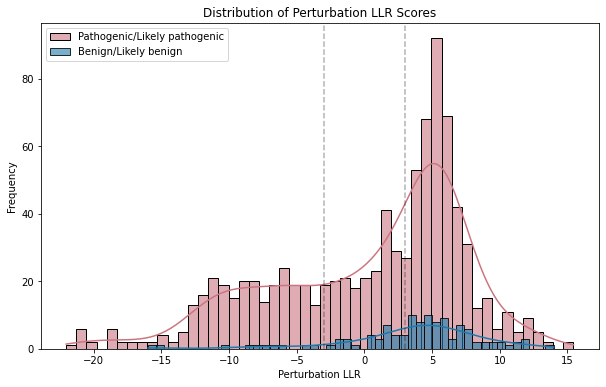

Pathogenic variants: 907
Benign variants: 116


In [ ]:
# plot histogram of perturbation_LLR of pathogenic and benign variants
# Filter for pathogenic and benign variants
pathogenic_df = df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
)
benign_df = df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
)

# Create figure
plt.figure(figsize=(10, 6))

# Plot histograms
sns.histplot(
    pathogenic_df["perturbation_LLR"].to_numpy(), 
    bins=50, 
    kde=True, 
    color="#CA7682",
    label="Pathogenic/Likely pathogenic",
    alpha=0.6
)
sns.histplot(
    benign_df["perturbation_LLR"].to_numpy(), 
    bins=50, 
    kde=True, 
    color="#1D7AAB",
    label="Benign/Likely benign",
    alpha=0.6
)

plt.title("Distribution of Perturbation LLR Scores")
plt.xlabel("Perturbation LLR")
plt.ylabel("Frequency")
plt.legend()
plt.axvline(x=-3, color='black', linestyle='--', alpha=0.3, label='Low threshold')
plt.axvline(x=3, color='black', linestyle='--', alpha=0.3, label='High threshold')
plt.show()

# Print summary statistics
print(f"Pathogenic variants: {pathogenic_df.shape[0]}")
print(f"Benign variants: {benign_df.shape[0]}")

In [ ]:
df = df.with_columns(
    pl.when(pl.col('perturbation_LLR').is_null())
    .then(pl.lit(None))
    .when(pl.col('perturbation_LLR') <= -3)
    .then(pl.lit('perturbed'))
    .when(pl.col('perturbation_LLR') >= 3)
    .then(pl.lit('unperturbed'))
    .otherwise(pl.lit('uncertain'))
    .alias('perturbation_status')
)

df = df.to_pandas()

In [ ]:
def edgotype_status(status_list):
    status_list = status_list.to_list()
    if len(status_list) == 1:
        return np.nan
    if pd.isnull(status_list).all():
        return np.nan
    if 'perturbed' in status_list and 'unperturbed' in status_list:
        return 'edgetic'
    elif status_list.count('perturbed') >= 2:
        return 'quasi-null'
    elif status_list.count('unperturbed') >= 2:
        return 'quasi-wildtype'
    else:
        return 'uncertain'

# N PPIs, N successful, N_perturbed, N_unperturbed, N-uncertain
edgotype = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(edgotype_status)
)

In [ ]:
edgotype = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(edgotype_status)
)
edgotype = edgotype.to_frame().rename(columns={"perturbation_status": "edgotype_status"})
edgotype['n_ppi'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["ad_symbol"]
    .nunique())
edgotype['n_measured_ppi'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["log2fc"]
    .apply(lambda x: x.notnull().sum()))

for status in ['perturbed', 'unperturbed', 'uncertain']:
    edgotype[f'n_{status}'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(lambda x: (x == status).sum()))
# TODO
#   - edgotype confidence score
edgotype = edgotype.reset_index()

n_b4 = edgotype.shape[0]
edgotype = pd.merge(edgotype, 
         df.loc[:, ['symbol', 
                    'gene_variant',
                    # 'cv_clinical_significance',
                    'clinvar_clnsig_clean',
                    # 'mondo_ids',
                    # 'blosum62',
                    # 'phyloP',
                    # 'allele_frequency',
                    # 'moi',
                    # 'am_pathogenicity',
                    # 'pLDDT',
                    # 'RSA',
                    # 'is_disordered',
                    ]].drop_duplicates(),
            on=["gene_variant"],
            how='left')

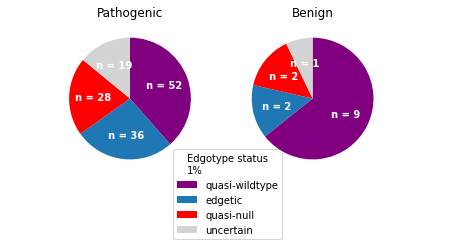

In [ ]:
order = ['quasi-wildtype', 'edgetic', 'quasi-null', 'uncertain']

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6,12))
for cat, ax in zip(['Pathogenic', 'Benign'], axs):
    vc = (edgotype.loc[(edgotype['clinvar_clnsig_clean'] == cat)
                 & (edgotype['n_measured_ppi'] >= 2), 
                 'edgotype_status']
                 .value_counts(dropna=True)
                 .reindex(order))
    vc.plot.pie(ax=ax,
                autopct=lambda x: f"n = {x / 100 * vc.sum():.0f}",
                startangle=90,
                counterclock=False,
                colors=['purple', 'C0', 'red', 'lightgrey'],
                ylabel='',
                textprops={'color': 'white', 'weight': 'bold'},
                legend=True if cat == 'Pathogenic' else False,
                )
    ax.set_title(cat)
leg = axs[0].get_legend()
leg.set_title("Edgotype status\n1%")
leg.set_loc("upper left")
leg.set_bbox_to_anchor((0.75, 0.2))

In [ ]:
edgotype[(edgotype.clinvar_clnsig_clean == 'Benign') & 
         (edgotype.edgotype_status == edgotype.edgotype_status)
         ]

,gene_variant,edgotype_status,n_ppi,n_measured_ppi,n_perturbed,n_unperturbed,n_uncertain,symbol,clinvar_clnsig_clean
8,ACSF3_Pro285Leu,quasi-null,3,3,3,0,0,ACSF3,Benign
65,BAG3_Arg258Trp,quasi-wildtype,10,10,0,9,1,BAG3,Benign
67,BAG3_Pro380Ser,quasi-wildtype,14,14,0,9,5,BAG3,Benign
123,GRN_Ser120Tyr,uncertain,7,7,0,1,6,GRN,Benign
124,GRN_Thr182Met,quasi-wildtype,7,7,0,5,2,GRN,Benign
196,KCNJ2_Ile258Thr,quasi-null,2,2,2,0,0,KCNJ2,Benign
242,KRT8_Gly434Ser,edgetic,5,5,1,2,2,KRT8,Benign
244,KRT8_Tyr54His,edgetic,5,5,1,4,0,KRT8,Benign
267,LITAF_Val81Met,quasi-wildtype,15,15,0,10,5,LITAF,Benign
275,MLH1_Lys751Arg,quasi-wildtype,17,17,0,17,0,MLH1,Benign


In [ ]:
df[df['gene_variant'] == 'KRT8_Tyr54His']

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,manual_correction_applied,consensus_score,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc,ppi_group_clean,error_log2fc,perturbation_LLR,perturbation_status
120,VUSAPWT1B2r05_028,C19,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,54668,None,...,False,466.134014,15.704667,2.0,502.003669,-0.106732,KRT8_KRT40_Tyr54His,0.5,5.038160,unperturbed
1010,VUSAPWT1B2r05_028,M17,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,100015084,None,...,False,30.113915,15.704667,2.0,446.175236,-3.845208,KRT8_KRT28_Tyr54His,0.5,-3.903793,perturbed
1451,VUSAPWT1B2r03_028,E19,VUSAPWT1B2r03_025_026_027_028_029_030,VUSAPWT1B2,r09,LWH1,1,False,71152,None,...,False,392.006182,21.930075,NaN,346.342249,0.178194,KRT8_KRT36_Tyr54His,0.5,6.448758,unperturbed
1452,VUSAPWT1B2r05_028,A19,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,100011278,None,...,False,437.845354,15.704667,2.0,270.660504,0.691908,KRT8_KRT16_Tyr54His,0.5,9.601829,unperturbed
1607,VUSAPWT1B2r05_028,O17,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,100066360,None,...,False,504.340548,15.704667,4.0,386.407146,0.383405,KRT8_KRT27_Tyr54His,0.5,7.612034,unperturbed


Log2FC at LLR = -3 (Perturbed):     -3.4624
Log2FC at LLR = 3  (Not Perturbed): -0.6364


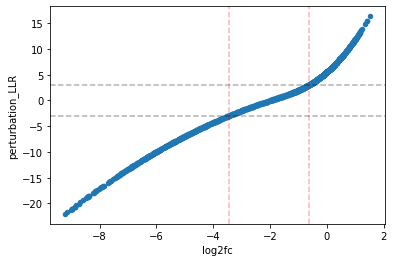

In [ ]:
import numpy as np

# 1. Sort the data by LLR to ensure interpolation works correctly
df_sorted = df.sort_values('perturbation_LLR')

# 2. Use numpy.interp to solve for x (log2fc) given y (LLR)
# We swap x and y: np.interp(target_y, current_y, current_x)
cutoff_lower_log2fc = np.interp(-3, df_sorted['perturbation_LLR'], df_sorted['log2fc'])
cutoff_upper_log2fc = np.interp(3, df_sorted['perturbation_LLR'], df_sorted['log2fc'])

print(f"Log2FC at LLR = -3 (Perturbed):     {cutoff_lower_log2fc:.4f}")
print(f"Log2FC at LLR = 3  (Not Perturbed): {cutoff_upper_log2fc:.4f}")

df.plot.scatter(x='log2fc', y='perturbation_LLR')
plt.axhline(y=-3, color='black', linestyle='--', alpha=0.3)
plt.axhline(y=3, color='black', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_lower_log2fc, color='red', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_upper_log2fc, color='red', linestyle='--', alpha=0.3)
plt.show()

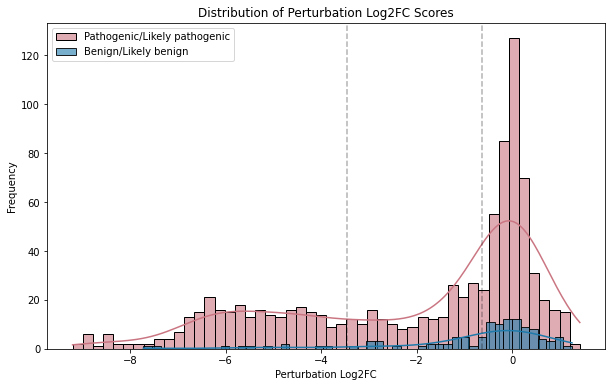

Pathogenic variants: 907
Benign variants: 116


In [ ]:
# plot histogram of log2fc of pathogenic and benign variants
# Filter for pathogenic and benign variants

df = pl.DataFrame(df)

pathogenic_df = df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
)
benign_df = df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
)

# Create figure
plt.figure(figsize=(10, 6))

# Plot histograms
sns.histplot(
    pathogenic_df["log2fc"].to_numpy(), 
    bins=50, 
    kde=True, 
    color="#CA7682",
    label="Pathogenic/Likely pathogenic",
    alpha=0.6
)
sns.histplot(
    benign_df["log2fc"].to_numpy(), 
    bins=50, 
    kde=True, 
    color="#1D7AAB",
    label="Benign/Likely benign",
    alpha=0.6
)

plt.title("Distribution of Perturbation Log2FC Scores")
plt.xlabel("Perturbation Log2FC")
plt.ylabel("Frequency")
plt.legend()
plt.axvline(x=-3.4624, color='black', linestyle='--', alpha=0.3, label='Low threshold')
plt.axvline(x=-0.6364, color='black', linestyle='--', alpha=0.3, label='High threshold')
plt.show()

# Print summary statistics
print(f"Pathogenic variants: {pathogenic_df.shape[0]}")
print(f"Benign variants: {benign_df.shape[0]}")

In [ ]:
df.columns

Index(['scoring_pla', 'scoring_pos', 'large_plate_name', 'retest_batch',
       'condition', 'condition_name', 'assay_id', 'media_control', 'ad_orf_id',
       'ad_mut_id', 'db_orf_id', 'db_mut_id', 'db_source_plate',
       'db_source_well', 'ad_source_plate', 'ad_source_well',
       'per_well_integrated_intensity_gray', 'manual_score_growth',
       'total_colony_area', 'Children_reExpandedColonies_Count', 'unique_id',
       'manual_score_growth_updated', 'contamination', 'outlier_score',
       'outlier_size_score', 'outlier_flag', 'size_score_raw', 'size_score',
       'ad_symbol', 'symbol', 'gene_variant', 'aa_change',
       'clinvar_clnsig_clean_pp_strict', 'splicing_variant', 'db_seq_final',
       'clinvar_clnsig_clean', 'db_group', 'db_condition_group', 'ppi_group',
       'edge_group', 'seq_ad', 'seq_db', 'db_seq_final_right',
       'manual_correction_applied', 'consensus_score', 'aa_score',
       'consensus_manual_score_growth', 'wt_consensus_score', 'log2fc',
       'p

In [ ]:
df[[
       'symbol', 'aa_change','ad_symbol',
       'clinvar_clnsig_clean', 'log2fc',
       'perturbation_LLR',
       'perturbation_status']].to_csv('./tmp/edge_df_LLR.csv', index=False)

In [ ]:
df.to_pandas()

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,manual_correction_applied,consensus_score,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc,ppi_group_clean,error_log2fc,perturbation_LLR,perturbation_status
0,VUSAPWT1B1r05_016,C13,VUSAPWT1B1r05_013_014_015_016_017_018,VUSAPWT1B1,r11,LWH25,1,False,11567,None,...,False,428.818896,86.686160,3.0,511.986940,-0.255193,LITAF_TAX1BP1_Pro51Ser,0.5,4.393518,unperturbed
1,VUSAPWT2B1r03_002,K07,VUSAPWT2B1r03_001_002_003_004_005_006,VUSAPWT2B1,r15,LWH1,2,False,53626,None,...,False,126.394540,31.660318,NaN,252.638062,-0.993468,GRN_LCE4A_Ser120Tyr,0.5,1.990671,uncertain
2,VUSAPWT2B1r05_014,G07,VUSAPWT2B1r05_013_014_015_016_017_018,VUSAPWT2B1,r17,LWH25,2,False,100014221,None,...,False,113.221590,9.408230,0.0,502.055578,-2.138882,UBQLN2_WFDC12_Pro506Thr,0.5,-0.273191,uncertain
3,VUSAPWT1B1r04_039,G15,VUSAPWT1B1r04_037_038_039_040_041_042,VUSAPWT1B1,r10,LWH10,1,False,11922,None,...,False,39.931179,0.812773,2.0,344.815113,-3.078729,MLH1_MYOG_Gly244Asp,0.5,-2.146447,uncertain
4,VUSAPWT1B1r05_033,M11,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,4761,None,...,False,151.357347,35.202996,1.0,321.813085,-1.083240,MLH1_AP2B1_Gly147Arg,0.5,1.773545,uncertain
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1854,VUSAPWT2B1r05_016,C15,VUSAPWT2B1r05_013_014_015_016_017_018,VUSAPWT2B1,r17,LWH25,2,False,14232,None,...,True,192.587341,5.394695,2.0,584.224106,-1.596005,PLP1_NRG1_Thr43Ile,0.5,0.717375,uncertain
1855,VUSAPWT1B1r05_033,C23,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,4621,None,...,False,519.264097,6.377880,4.0,543.312732,-0.065192,TPM1_KXD1_Ala63Val,0.5,5.229411,unperturbed
1856,VUSAPWT1B2r05_040,G01,VUSAPWT1B2r05_037_038_039_040_041_042,VUSAPWT1B2,r11,LWH25,1,False,2860,None,...,False,503.392454,14.200527,4.0,589.149416,-0.226534,HPRT1_PRTFDC1_Gly58Arg,0.5,4.513302,unperturbed
1857,VUSAPWT6B1r05_019,E07,VUSAPWT6B1r05_019_020_021_022_023_024,VUSAPWT6B1,r17,LWH25,6,False,6281,None,...,False,9.973253,7.081247,0.0,462.529997,-5.400599,KCNJ2_KCNJ15_Thr400Met,0.5,-8.113502,perturbed
